In [7]:
import pandas as pd
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, LSTM, Dense, Embedding
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
import matplotlib.pyplot as plt

In [8]:
# İlk çalıştırmada gerekli NLTK veri paketlerini indir
nltk.download('stopwords')
nltk.download('punkt')


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!


True

Epoch 1/300
10/10 ━━━━━━━━━━━━━━━━━━━━ 3s 58ms/step - accuracy: 0.3605 - loss: 5.1428 - val_accuracy: 0.5000 - val_loss: 4.3468
Epoch 2/300
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.4983 - loss: 3.5839 - val_accuracy: 0.5000 - val_loss: 2.2539
Epoch 3/300
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.4978 - loss: 2.1695 - val_accuracy: 0.5000 - val_loss: 1.6765
Epoch 4/300
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.6798 - loss: 1.5711 - val_accuracy: 0.7500 - val_loss: 1.5775
Epoch 5/300
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.7479 - loss: 1.4167 - val_accuracy: 0.7500 - val_loss: 1.5939
Epoch 6/300
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.7479 - loss: 1.3735 - val_accuracy: 0.7500 - val_loss: 1.5970
Epoch 7/300
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.7486 - loss: 1.3441 - val_accuracy: 0.7500 - val_loss: 1.6204
Epoch 8/300
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.7489 - loss: 1.3212 - val_accuracy: 0.

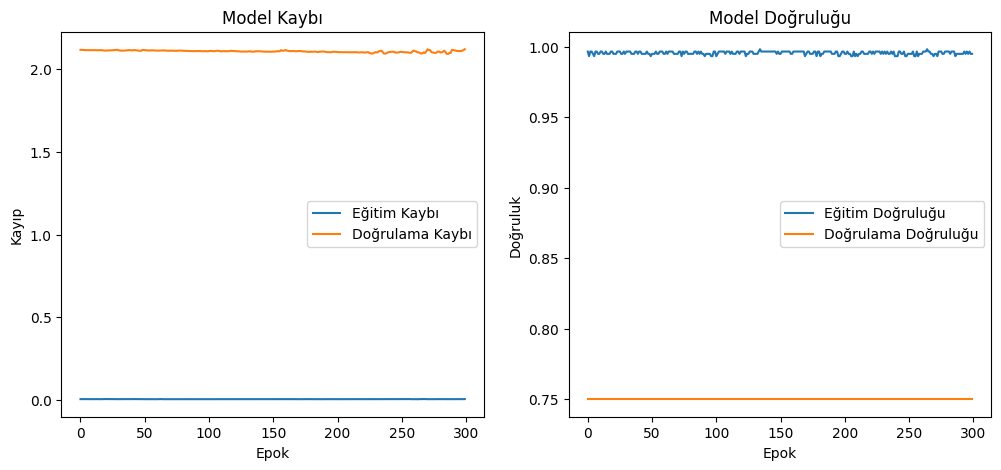

In [9]:
# 1️⃣ Veri setini yükleme
df = pd.read_excel("/content/ceviri_veri_seti_200.xlsx")
turkish_sentences = df["Turkish"].astype(str).tolist()
english_sentences = df["English"].astype(str).tolist()

# 2️⃣ Tokenizer ayarı
num_words = 2000
src_tokenizer = Tokenizer(num_words=num_words, filters='')
tar_tokenizer = Tokenizer(num_words=num_words, filters='')

src_tokenizer.fit_on_texts(turkish_sentences)
tar_tokenizer.fit_on_texts(english_sentences)

# Hedef cümlelerin başına 'start' sonuna 'end' ekleyelim
target_sentences_input = ["startseq "+sent+" endseq" for sent in english_sentences]
tar_tokenizer.fit_on_texts(target_sentences_input)

# 3️⃣ Sekanslara dönüştürme
encoder_input_sequences = src_tokenizer.texts_to_sequences(turkish_sentences)
decoder_input_sequences = tar_tokenizer.texts_to_sequences(target_sentences_input)
decoder_target_sequences = tar_tokenizer.texts_to_sequences([sent+" endseq" for sent in english_sentences])

max_encoder_seq_length = max(len(seq) for seq in encoder_input_sequences)
max_decoder_seq_length = max(len(seq) for seq in decoder_input_sequences)

encoder_input_sequences = pad_sequences(encoder_input_sequences, maxlen=max_encoder_seq_length, padding='post')
decoder_input_sequences = pad_sequences(decoder_input_sequences, maxlen=max_decoder_seq_length, padding='post')
decoder_target_sequences = pad_sequences(decoder_target_sequences, maxlen=max_decoder_seq_length, padding='post')

# 4️⃣ Model oluşturma
latent_dim = 256
vocab_size_src = len(src_tokenizer.word_index) + 1
vocab_size_tar = len(tar_tokenizer.word_index) + 1

encoder_inputs = Input(shape=(None,))
enc_emb = Embedding(vocab_size_src, latent_dim)(encoder_inputs)
encoder_lstm = LSTM(latent_dim, return_state=True)
encoder_outputs, state_h, state_c = encoder_lstm(enc_emb)
encoder_states = [state_h, state_c]

decoder_inputs = Input(shape=(None,))
dec_emb_layer = Embedding(vocab_size_tar, latent_dim)
dec_emb = dec_emb_layer(decoder_inputs)
decoder_lstm = LSTM(latent_dim, return_sequences=True, return_state=True)
decoder_outputs, _, _ = decoder_lstm(dec_emb, initial_state=encoder_states)
decoder_dense = Dense(vocab_size_tar, activation='softmax')
decoder_outputs = decoder_dense(decoder_outputs)

model = Model([encoder_inputs, decoder_inputs], decoder_outputs)
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

# 5️⃣ Model eğitimi
epochs = 300
batch_size = 16

model.fit(
    [encoder_input_sequences, decoder_input_sequences],
    np.expand_dims(decoder_target_sequences, -1),
    batch_size=batch_size,
    epochs=epochs,
    validation_split=0.2
)

history = model.fit(
    [encoder_input_sequences, decoder_input_sequences],
    np.expand_dims(decoder_target_sequences, -1),
    batch_size=batch_size,
    epochs=epochs,
    validation_split=0.2
)

model.save("model.h5")

plt.figure(figsize=(12, 5)),

plt.subplot(1, 2, 1)

plt.plot(history.history['loss'], label='Eğitim Kaybı')
plt.plot(history.history['val_loss'], label='Doğrulama Kaybı')
plt.title('Model Kaybı')
plt.xlabel('Epok')
plt.ylabel('Kayıp')
plt.legend()

plt.subplot(1, 2, 2)

plt.plot(history.history['accuracy'], label='Eğitim Doğruluğu')
plt.plot(history.history['val_accuracy'], label='Doğrulama Doğruluğu')
plt.title('Model Doğruluğu')
plt.xlabel('Epok')
plt.ylabel('Doğruluk')
plt.legend()

plt.show()


# 6️⃣ Çeviri yapmak için encoder ve decoder inference modelleri kurulur
# Eğer istersen bu aşamada da devam ettirebilir, anlık kelime girip çeviri alacak inference kodlarını ekleyebilirim.
